SEABORN DATA NUMERIK


In [1]:
import pandas as pd
from warnings import filterwarnings
import seaborn as sns
import matplotlib.pyplot as plt 

filterwarnings('ignore')

source = pd.read_csv('penyakit_jantung.csv')
source

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,female,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,female,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,male,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,female,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,male,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,male,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,female,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,female,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,female,0,130,131,0,1,115,1,1.2,1,1,3,0


In [2]:
result = source[["trestbps","chol","thalach"]]
result

,trestbps,chol,thalach
0,145,233,150
1,130,250,187
2,130,204,172
3,120,236,178
4,120,354,163
...,...,...,...
298,140,241,123
299,110,264,132
300,144,193,141
301,130,131,115


In [3]:
sns.set()

DISTRIBUTION PLOT


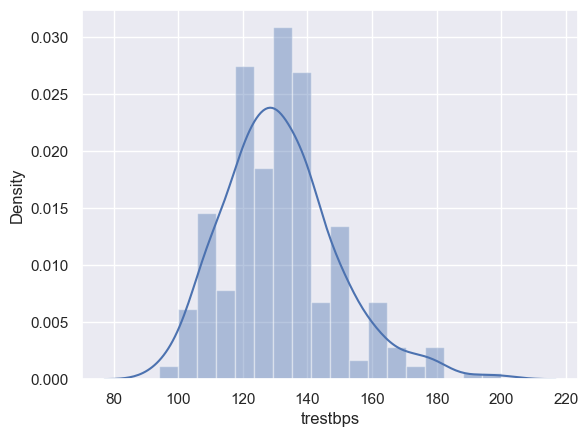

In [4]:
sns.distplot(result.trestbps);

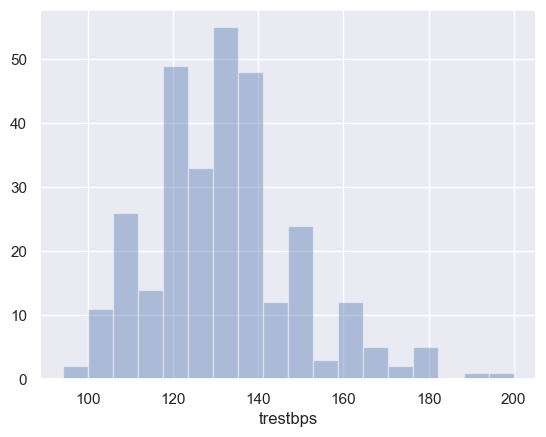

In [5]:
sns.distplot(result.trestbps, kde=False); # kde = kernel density estimation

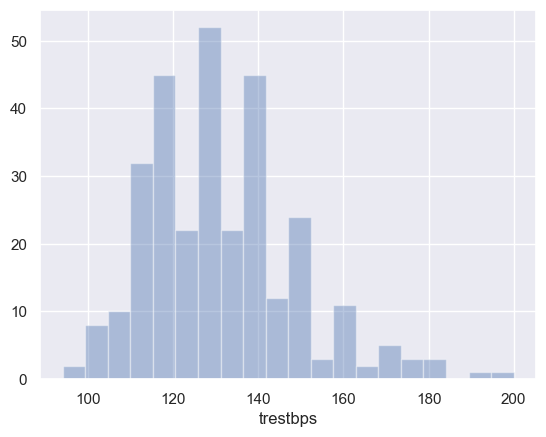

In [6]:
sns.distplot(result.trestbps, kde=False, bins = 20);

SCATTERPLOT


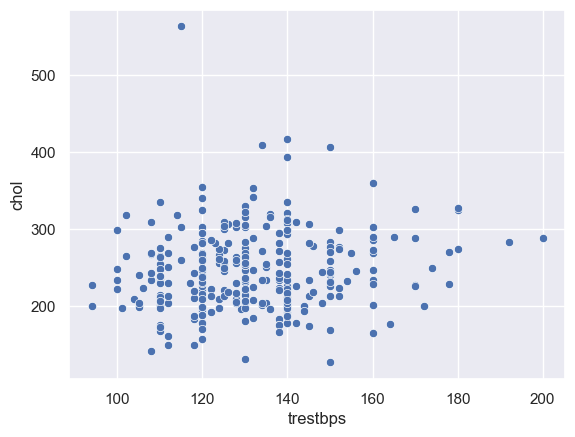

In [7]:
sns.scatterplot(x="trestbps", y="chol", data=result);

KDEPLOT

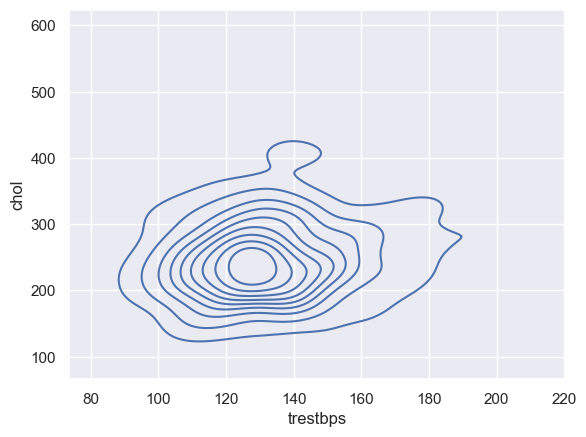

In [8]:
sns.kdeplot(x="trestbps", y="chol", data=result);

REGPLOT

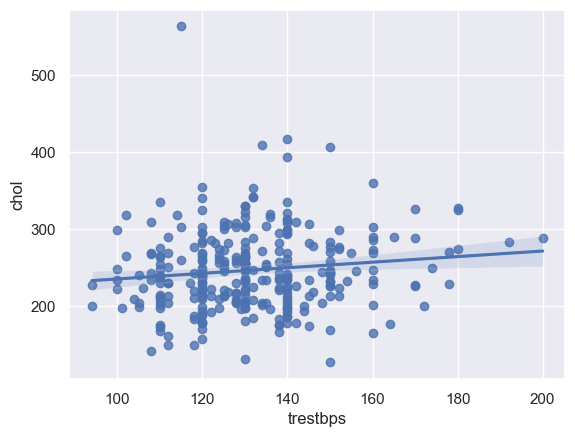

In [9]:
sns.regplot(x="trestbps", y="chol", data=result);

JOINT PLOT


In [10]:
result.head()

,trestbps,chol,thalach
0,145,233,150
1,130,250,187
2,130,204,172
3,120,236,178
4,120,354,163


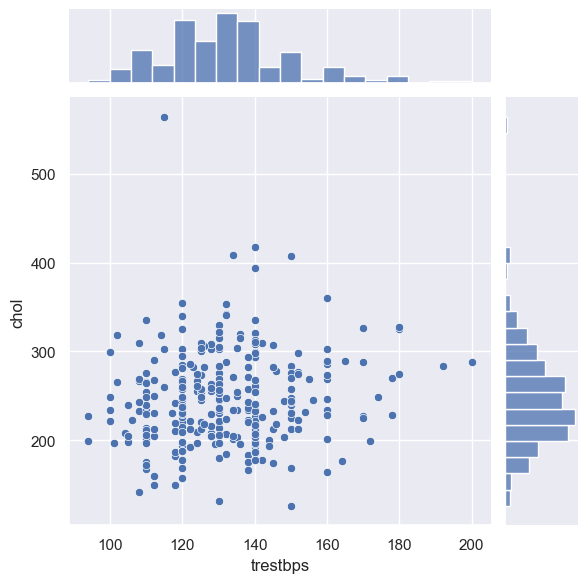

In [11]:
sns.jointplot(x="trestbps", y="chol", data=result);

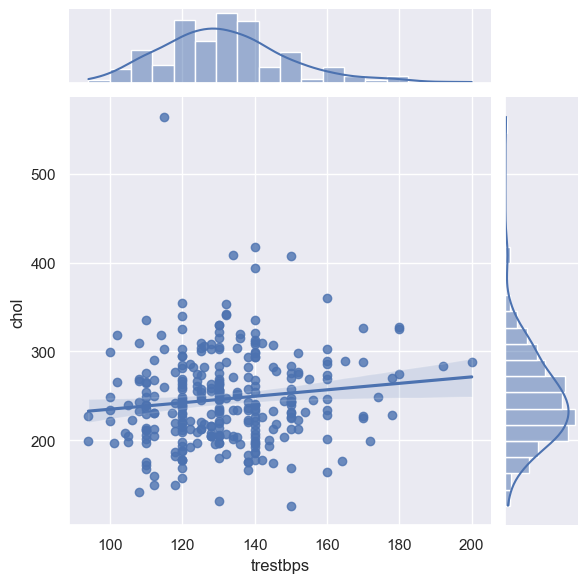

In [12]:
sns.jointplot(x="trestbps", y="chol", kind='reg', data=source);

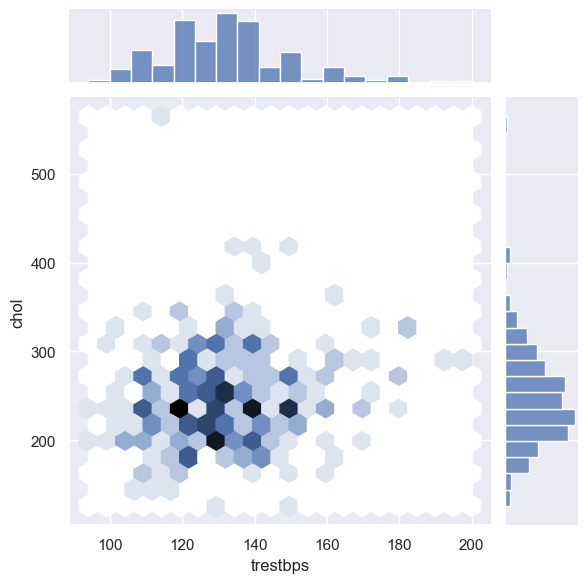

In [13]:
sns.jointplot(x="trestbps", y="chol", kind='hex', data=result);

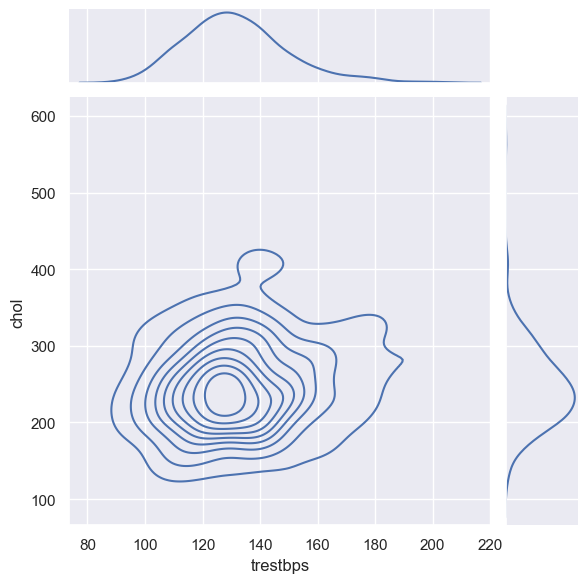

In [14]:
sns.jointplot(x="trestbps", y="chol", kind='kde', data=source);

PAIRPLOT


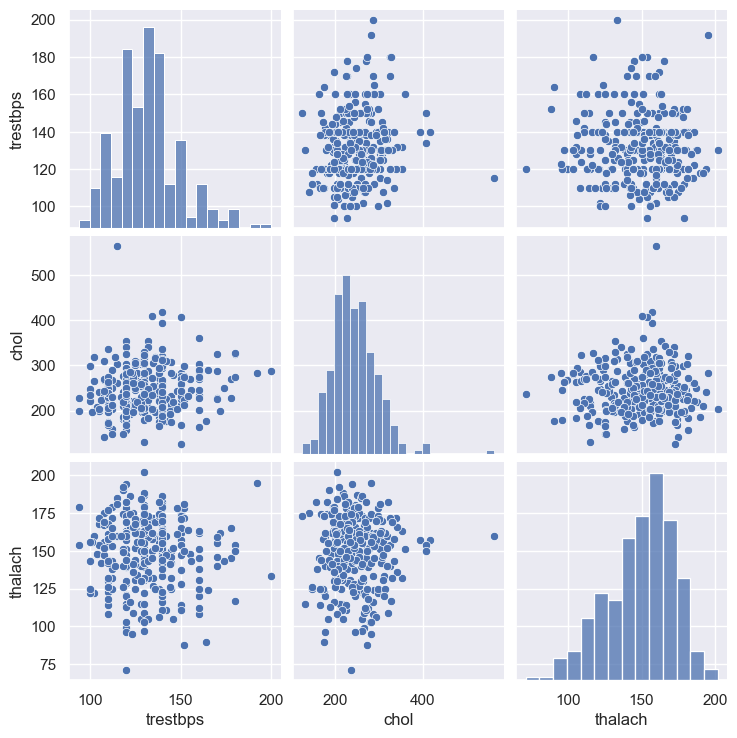

In [15]:
sns.pairplot(result)

Exception ignored in: <function WeakKeyDictionary.__init__.<locals>.remove at 0x000001829B77F2E0>
Traceback (most recent call last):
  File "c:\Users\agung\AppData\Local\Programs\Python\Python312\Lib\weakref.py", line 370, in remove
    self = selfref()
           ^^^^^^^^^
KeyboardInterrupt: 


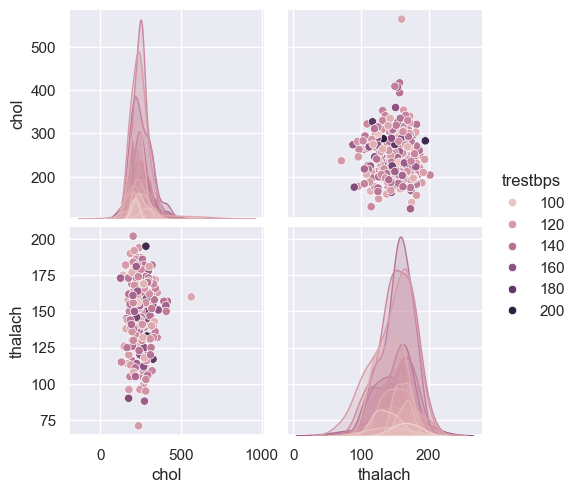

In [16]:
sns.pairplot(result, hue = 'trestbps')

PAIRGRID

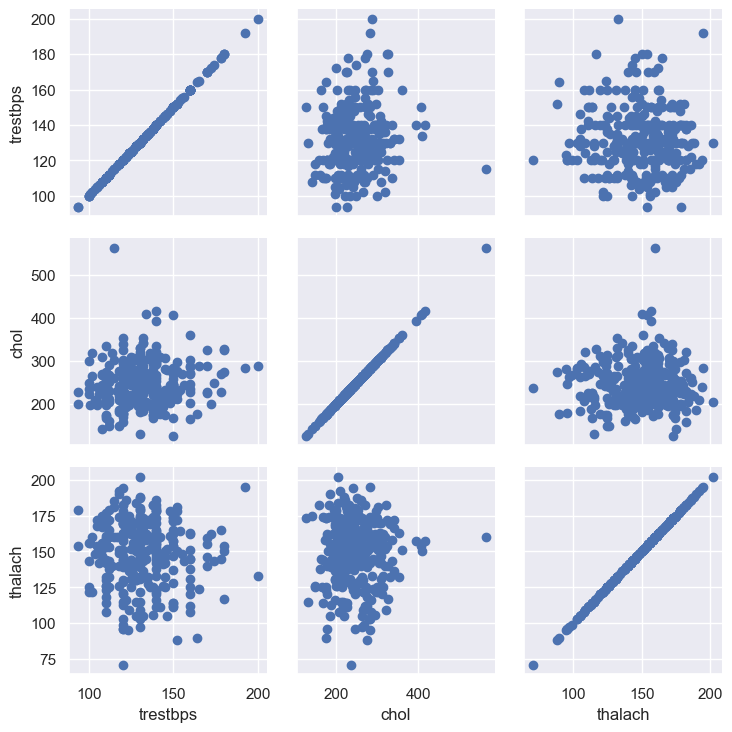

In [ ]:
p = sns.PairGrid(result)
p.map(plt.scatter)
plt.show()

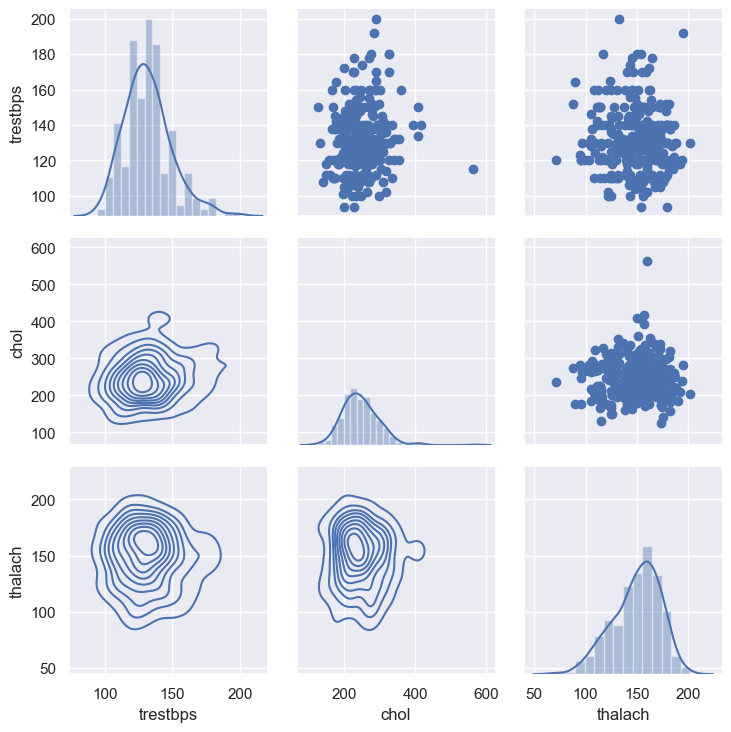

In [ ]:
p = sns.PairGrid(result)
p.map_diag(sns.distplot)
p.map_upper(plt.scatter)
p.map_lower(sns.kdeplot)

HEATMAP


In [ ]:
result.head()

,trestbps,chol,thalach
0,145,233,150
1,130,250,187
2,130,204,172
3,120,236,178
4,120,354,163


In [ ]:
# heatmap datanya harus berupa matrix

kor = result.corr()
kor

,trestbps,chol,thalach
trestbps,1.000000,0.123174,-0.046698
chol,0.123174,1.000000,-0.009940
thalach,-0.046698,-0.009940,1.000000


<Axes: >

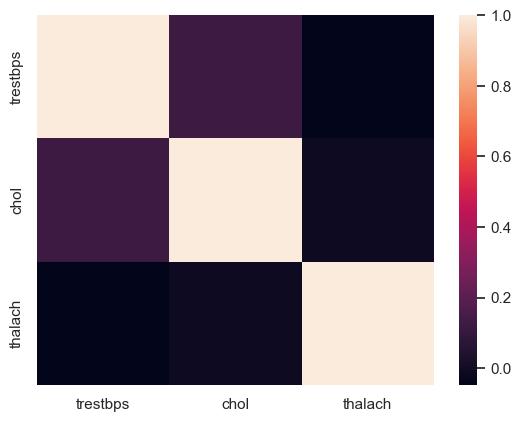

In [ ]:
sns.heatmap(kor)

<Axes: >

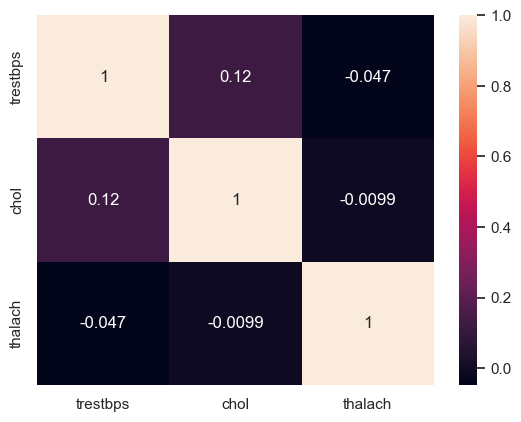

In [ ]:
sns.heatmap(kor, annot = True)

<Axes: >

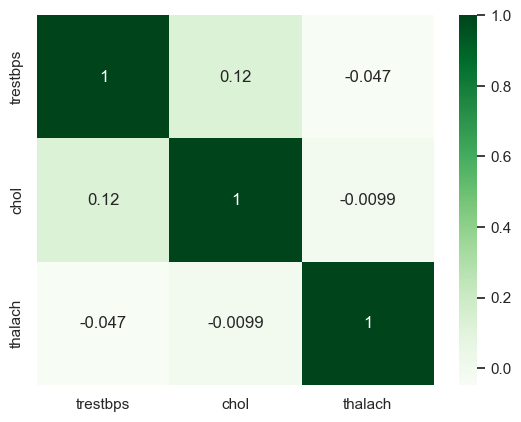

In [ ]:
sns.heatmap(kor, annot = True, cmap = "Greens")

# cmaps digunakan untuk merubah warna heatmap

In [ ]:
source2 = pd.read_csv("penyakit_jantung.csv", index_col="sex")
source2

,age,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
sex,,,,,,,,,,,,,
female,63,3,145,233,1,0,150,0,2.3,0,0,1,1
female,37,2,130,250,0,1,187,0,3.5,0,0,2,1
male,41,1,130,204,0,0,172,0,1.4,2,0,2,1
female,56,1,120,236,0,1,178,0,0.8,2,0,2,1
male,57,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
male,57,0,140,241,0,1,123,1,0.2,1,0,3,0
female,45,3,110,264,0,1,132,0,1.2,1,0,3,0
female,68,0,144,193,1,1,141,0,3.4,1,2,3,0


In [ ]:
result2 = source2.iloc[:, [0, 2, 3]]
result2

,age,trestbps,chol
sex,,,
female,63,145,233
female,37,130,250
male,41,130,204
female,56,120,236
male,57,120,354
...,...,...,...
male,57,140,241
female,45,110,264
female,68,144,193


<Axes: ylabel='sex'>

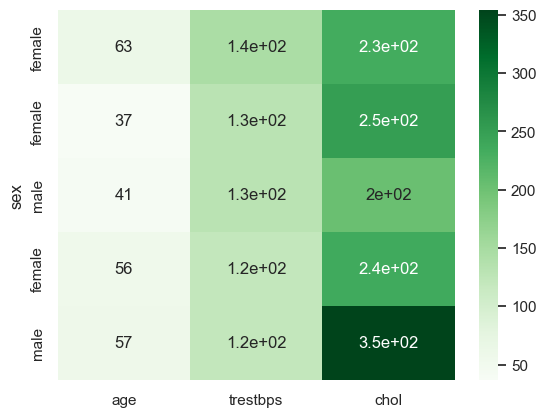

In [ ]:
sns.heatmap(result2.head(), annot=True, cmap='Greens')

HEATMAP PIVOT TABLE

In [ ]:
pivot = source2.pivot_table(index="sex", columns="age", values="chol")
pivot = pivot.fillna(0)
pivot

age,29,34,35,37,38,39,40,41,42,43,...,65,66,67,68,69,70,71,74,76,77
sex,,,,,,,,,,,,,,,,,,,,,
female,204.0,182.0,224.0,250.0,193.666667,270.0,196.333333,205.166667,250.0,250.0,...,240.25,247.0,252.833333,248.0,244.0,252.5,0.000000,0.0,0.0,304.0
male,0.0,210.0,183.0,215.0,0.000000,209.5,0.000000,244.000000,237.0,277.0,...,317.75,244.0,354.666667,211.0,239.0,0.0,238.666667,269.0,197.0,0.0


<Axes: xlabel='age', ylabel='sex'>

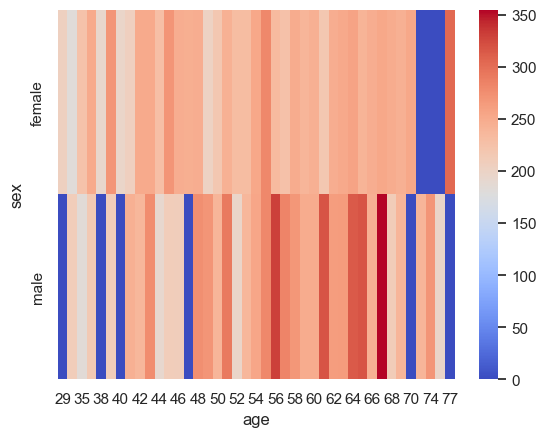

In [ ]:
sns.heatmap(pivot, cmap="coolwarm")

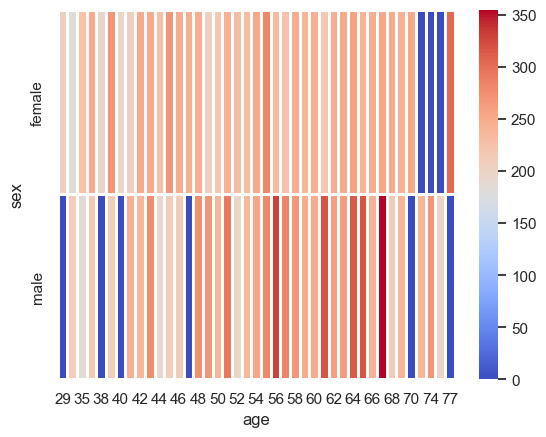

In [ ]:
sns.heatmap(pivot, cmap="coolwarm", linecolor="white", linewidths=1);

CLUSTER MAP

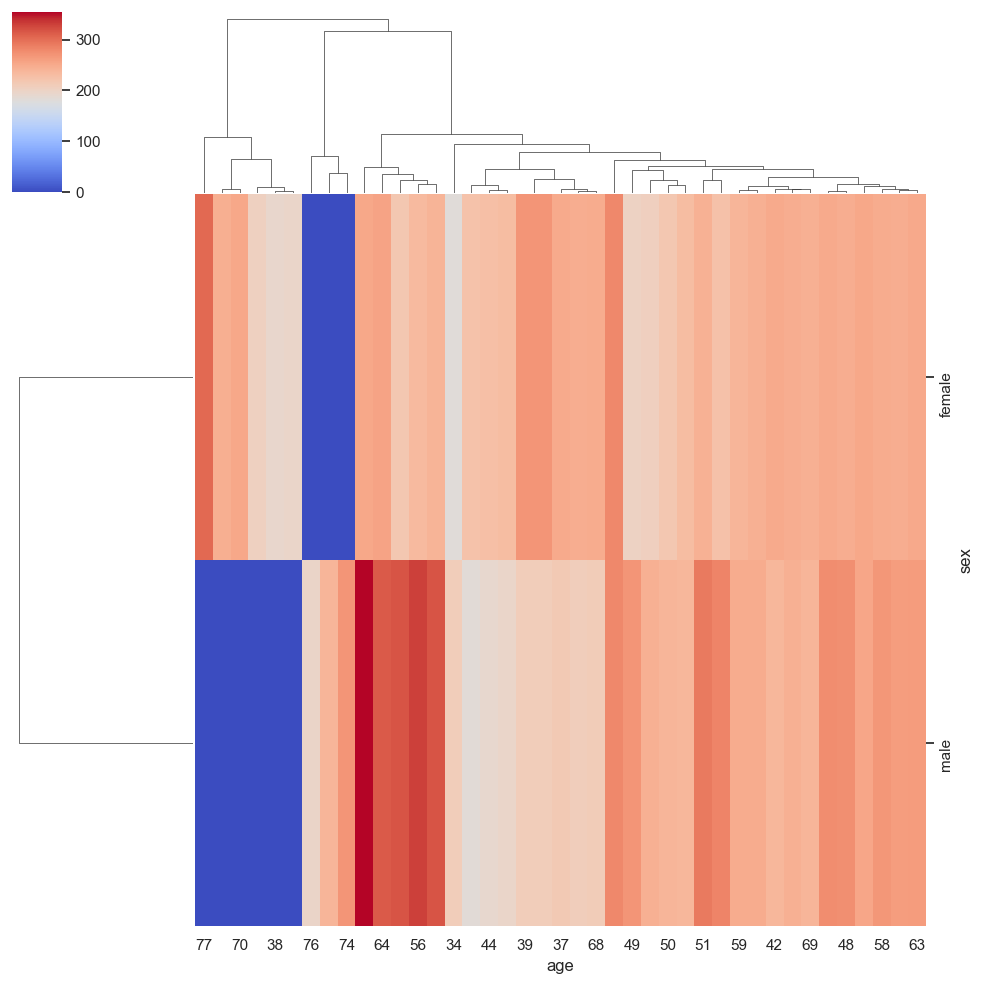

In [ ]:
sns.clustermap(pivot, cmap="coolwarm")

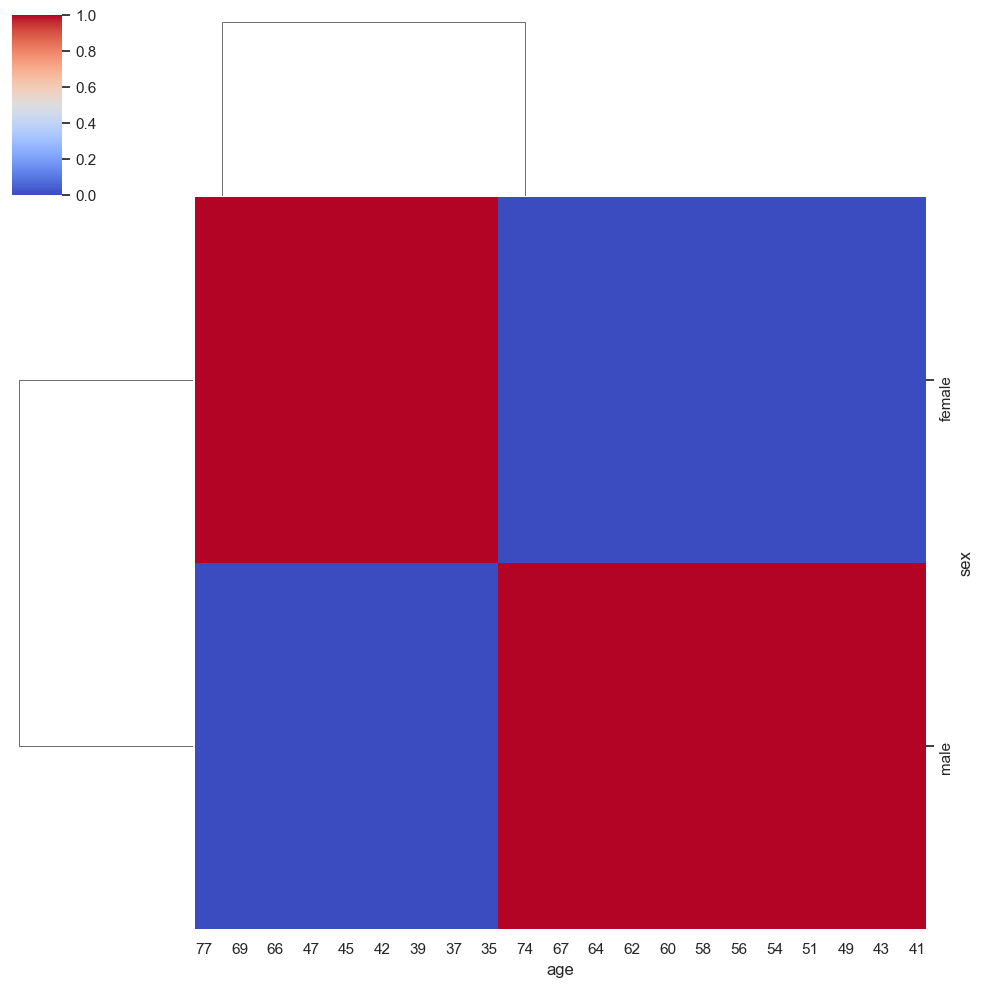

In [ ]:
sns.clustermap(pivot, cmap="coolwarm", standard_scale=1)

# standard_scale digunakan untuk mengubah value menjadi 0 - 1

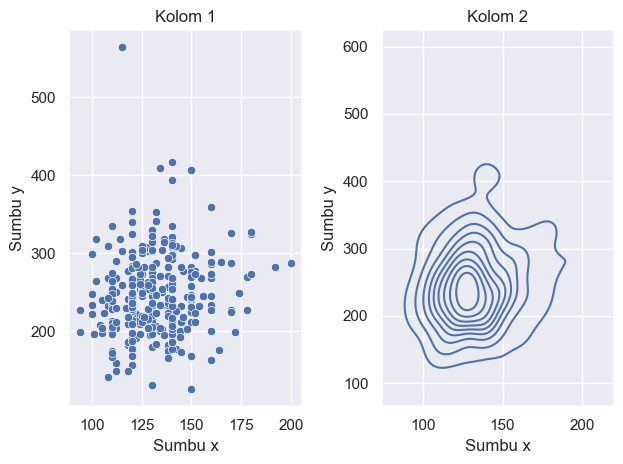

In [ ]:
fig, axes = plt.subplots(1, 2) # (baris, kolom)

# kolom 1
sns.scatterplot(x=result["trestbps"], y = result["chol"], ax = axes[0])
axes[0].set_xlabel('Sumbu x')
axes[0].set_ylabel('Sumbu y')
axes[0].set_title('Kolom 1')

# kolom 2
sns.kdeplot(x=result['trestbps'], y=result['chol'], ax=axes[1])
axes[1].set_xlabel('Sumbu x')
axes[1].set_ylabel('Sumbu y')
axes[1].set_title('Kolom 2')

fig.tight_layout()
plt.show()